© 2026 Mechanome Bio. Proprietary and confidential.

# Nuclear shape gSEM — step 3 of 3: figures

**Kernel: Python** (Windows, same environment as the prep notebook; needs `matplotlib`, `pandas`, `scipy`). Gene labels on the volcano plots are placed by a small built-in routine that keeps them from overlapping each other, and every figure is checked for overlapping text before it is saved.

Draws every figure from the tables the R notebook saved in `outputs/<tissue>/plot_data/`, so **gSEM never needs to be re-run to change a figure**. Each figure is written to `outputs/<tissue>/figures/` as PNG (300 dpi), SVG and a `_metadata.json` file carrying the proprietary notice, axis labels, the statistical method and the source table.

House style comes from `src/figure_style.py` (a copy of the `mechanome-figure-style` module). No new statistical tests are run here: significance comes from gSEM (`lm(r_gene ~ r_metric)` on spatially detrended residuals) with a **Benjamini–Hochberg correction applied separately for each metric**, significant = adjusted p < 0.05.

| Figure | File stem | Source table(s) |
|---|---|---|
| Metric distributions | `metric_distributions` | `metric_values.csv` |
| Metric correlation before / after spatial detrending | `metric_collinearity_before_detrending`, `..._after_detrending` | same names `.csv` |
| Volcano plot per metric | `volcano_<metric>` | `volcano_<metric>.csv` |
| Significant genes per metric | `hit_counts` | `hit_counts.csv` |
| Significant genes shared between metrics | `hit_overlap` | `hit_overlap.csv` |
| Pancreas only: significant genes per cell type | `cell_type_hit_counts` | `cell_type_hit_counts.csv` |
| Pancreas only: cell-type-blocked volcano per metric | `volcano_blocked_<metric>` | `volcano_blocked_<metric>.csv` |


In [4]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 1: imports, folders and settings.
import sys
import json
from pathlib import Path

import numpy
import pandas
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors
import matplotlib.ticker
import matplotlib.text

REPOSITORY_FOLDER = Path.cwd().parent
sys.path.insert(0, str(REPOSITORY_FOLDER / "src"))
import figure_style  # Mechanome Bio house style (src/figure_style.py)


# Which tissues to draw. Each must already have outputs/<tissue>/plot_data/ from the R notebook.
DATASETS_TO_PLOT = ["pancreas", "lung"]

SHAPE_METRICS = ["solidity", "extent", "shape_index", "circularity", "perimeter", "axis_ratio"]

# Readable names and units for each metric (units go in brackets on axis labels).
METRIC_DISPLAY_NAMES = {
    "solidity": "Solidity", "extent": "Extent", "shape_index": "Shape index",
    "circularity": "Circularity", "perimeter": "Perimeter", "axis_ratio": "Axis ratio",
    "log_cell_area": "Log cell area",
}
METRIC_UNITS = {
    "solidity": "dimensionless", "extent": "dimensionless", "shape_index": "dimensionless",
    "circularity": "dimensionless", "perimeter": "µm", "axis_ratio": "dimensionless",
}

# Significance threshold. 0.05 on the Benjamini-Hochberg adjusted p value is the cut-off
# MB_05.2_spatial_regression_v2_extended.ipynb uses for its volcano plots (pCutoff = 0.05 on
# padj, no beta cut-off), and must match SIGNIFICANCE_PADJ in the R notebook.
SIGNIFICANCE_PADJ = 0.05

# Volcano plot colours (requested for this analysis):
#   significant with a positive regression coefficient (beta > 0) -> dark red
#   significant with a negative regression coefficient (beta < 0) -> house dark blue
#   not significant (adjusted p >= SIGNIFICANCE_PADJ)              -> grey
VOLCANO_POSITIVE_COLOUR = "#8B0000"                        # dark red
VOLCANO_NEGATIVE_COLOUR = figure_style.DEFAULT_DARK_BLUE   # "#1F3B73" from the house style
VOLCANO_NOT_SIGNIFICANT_COLOUR = "#A6A6A6"                 # mid grey

# How many significant genes to name on each side (beta > 0 and beta < 0) of each volcano plot.
# Genes are ranked by adjusted p value. Very strong genes often share the SAME adjusted p value
# (it bottoms out at the smallest number the computer can store), so ties are broken by the size
# of the t statistic (or of beta when no t statistic is saved, as in the cell-type-blocked tables).
N_LABEL_PER_SIDE = 15
HISTOGRAM_BINS = 60

# Text describing how significance was decided; written into every figure's metadata file.
GSEM_STATISTICS = {
    "test": "gSEM: lm(r_gene ~ r_metric) on residuals after mgcv::bam smooths "
            "s(centroid_x, centroid_y, k=300) + s(log_cell_area, k=10); metric log-transformed",
    "correction": "benjamini-hochberg, applied separately for each metric",
    "significance_threshold": f"adjusted p < {SIGNIFICANCE_PADJ}",
    "p_values": "every raw and adjusted p value is in the source table named in 'source_table'",
}


def read_plot_table(path, **options):
    '''Read a table written by the R notebook (its first line is the "# notice" line).'''
    return pandas.read_csv(path, comment="#", **options)


def metric_axis_label(metric):
    return f"{METRIC_DISPLAY_NAMES[metric]} ({METRIC_UNITS[metric]})"


def save(figure, folder, file_stem, title, x_label, y_label, source_tables, extra=None):
    '''Save PNG + SVG + metadata through the house-style module, then close the figure.'''
    information = {
        "dataset": folder.parent.name,
        "source_table": [str(path.relative_to(REPOSITORY_FOLDER)) for path in source_tables],
        "statistical_comparisons": GSEM_STATISTICS,
        "plot_data_run_record": str((folder.parent / "plot_data" / "plot_data_metadata.json").relative_to(REPOSITORY_FOLDER)),
    }
    if extra:
        information.update(extra)
    figure_style.save_figure(figure, str(folder / file_stem), title, x_label, y_label,
                             comparison_results=None, extra_information=information)
    plt.show()
    plt.close(figure)


figure_style.apply_house_style()
print("ready")

ready


In [5]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 2: plotting functions (one per figure type).


def text_items_on_figure(figure):
    '''
    Every visible piece of text on the figure with its on-screen box, as (description, box) pairs:
    titles, axis labels, tick labels, gene labels and the legend (as one box).
    '''
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    items = []

    def add(description, artist):
        if artist is None or not artist.get_visible():
            return
        if hasattr(artist, "get_text") and not artist.get_text().strip():
            return
        if isinstance(artist, matplotlib.text.Annotation):
            # An annotation's own box also covers its leader line; measure only the words.
            box = matplotlib.text.Text.get_window_extent(artist, renderer)
        else:
            box = artist.get_window_extent(renderer)
        items.append((description, box))

    if figure._suptitle is not None:
        add("figure title", figure._suptitle)
    for axes in figure.axes:
        add("title", axes.title)
        add("x axis label", axes.xaxis.label)
        add("y axis label", axes.yaxis.label)
        for tick_label in axes.get_xticklabels():
            add(f"x tick '{tick_label.get_text()}'", tick_label)
        for tick_label in axes.get_yticklabels():
            add(f"y tick '{tick_label.get_text()}'", tick_label)
        for text in axes.texts:
            add(f"label '{text.get_text()}'", text)
        add("legend", axes.get_legend())
    return items


def find_overlapping_text(figure):
    '''List every pair of text items whose boxes overlap (an empty list means no overlaps).'''
    items = text_items_on_figure(figure)
    overlapping_pairs = []
    for first in range(len(items)):
        for second in range(first + 1, len(items)):
            first_name, first_box = items[first]
            second_name, second_box = items[second]
            # Neighbouring tick labels on the same axis touch at the edges by design; only
            # report boxes that genuinely overlap by more than one pixel each way.
            overlap_width = min(first_box.x1, second_box.x1) - max(first_box.x0, second_box.x0)
            overlap_height = min(first_box.y1, second_box.y1) - max(first_box.y0, second_box.y0)
            if overlap_width > 1 and overlap_height > 1:
                overlapping_pairs.append((first_name, second_name))
    return overlapping_pairs


def segment_crosses_box(start, end, box):
    '''True if the straight line from start to end passes through the rectangle box (x0, y0, x1, y1).'''
    for fraction in numpy.linspace(0.05, 0.95, 25):   # check 25 evenly spaced points along the line
        x_value = start[0] + fraction * (end[0] - start[0])
        y_value = start[1] + fraction * (end[1] - start[1])
        if box[0] < x_value < box[2] and box[1] < y_value < box[3]:
            return True
    return False


def segments_cross(first_start, first_end, second_start, second_end):
    '''True if two straight lines cross each other (standard orientation test).'''
    def turn(a, b, c):
        return (b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0])
    return (turn(first_start, first_end, second_start) * turn(first_start, first_end, second_end) < 0 and
            turn(second_start, second_end, first_start) * turn(second_start, second_end, first_end) < 0)


def place_gene_labels(figure, axes, labelled_rows, all_x_values, all_y_values):
    '''
    Write each gene name next to its point without any two names overlapping.

    For every gene (most significant first) it tries positions on rings of growing distance
    around the point, in 16 directions. A position is allowed only if the name stays inside
    the plot and does not overlap a name already placed. Among allowed positions it picks the
    one that covers the fewest data points, then whose connecting line crosses the fewest other
    names and lines, then is closest to its point. A thin line joins each name to its point.
    Returns the names that could not be placed without overlapping another name.
    '''
    figure.canvas.draw()
    renderer = figure.canvas.get_renderer()
    pixels_per_point = figure.dpi / 72.0                  # converts screen pixels to font points
    data_to_pixels = axes.transData.transform
    axes_box = axes.get_window_extent(renderer)
    point_pixels = data_to_pixels(numpy.column_stack([all_x_values, all_y_values]))
    point_radius = 3 * pixels_per_point                   # roughly the drawn size of a dot

    directions = numpy.deg2rad(numpy.arange(0, 360, 22.5))
    distances = numpy.array([10, 16, 24, 34, 46, 60, 76, 94, 115, 140, 170]) * pixels_per_point
    gap = 1.5 * pixels_per_point                          # minimum empty space between two names

    placed_boxes = []
    placed_lines = []   # (point, label centre) for every name already placed
    could_not_place = []
    for row in labelled_rows.sort_values("neg_log10_padj", ascending=False).itertuples():
        anchor = data_to_pixels((row.beta, row.neg_log10_padj))
        label = axes.annotate(
            row.gene, xy=(row.beta, row.neg_log10_padj), xytext=(0, 0), textcoords="offset points",
            ha="center", va="center", zorder=5,
            arrowprops={"arrowstyle": "-", "color": "black", "linewidth": 0.5, "shrinkA": 0, "shrinkB": 2})
        label_box = matplotlib.text.Text.get_window_extent(label, renderer)   # the words only, not the line
        half_width, half_height = label_box.width / 2 + gap, label_box.height / 2 + gap

        best_choice = None   # (score, centre, box)
        for distance in distances:
            for direction in directions:
                centre = anchor + distance * numpy.array([numpy.cos(direction), numpy.sin(direction)])
                box = (centre[0] - half_width, centre[1] - half_height, centre[0] + half_width, centre[1] + half_height)
                inside_plot = (box[0] >= axes_box.x0 and box[2] <= axes_box.x1 and
                               box[1] >= axes_box.y0 and box[3] <= axes_box.y1)
                if not inside_plot:
                    continue
                if any(box[0] < other[2] and box[2] > other[0] and box[1] < other[3] and box[3] > other[1]
                       for other in placed_boxes):
                    continue
                covered_points = numpy.sum(
                    (point_pixels[:, 0] > box[0] - point_radius) & (point_pixels[:, 0] < box[2] + point_radius) &
                    (point_pixels[:, 1] > box[1] - point_radius) & (point_pixels[:, 1] < box[3] + point_radius))
                # Does this name's connecting line run through an earlier name, or cross an earlier line?
                crossings = sum(segment_crosses_box(anchor, centre, other) for other in placed_boxes)
                crossings += sum(segments_cross(anchor, centre, other_start, other_end)
                                 for other_start, other_end in placed_lines)
                # Does this name sit on top of an earlier name's connecting line?
                crossings += sum(segment_crosses_box(other_start, other_end, box)
                                 for other_start, other_end in placed_lines)
                # Covering a data point costs most, then a crossing line, then distance from the point.
                score = covered_points * 10000 + crossings * 1000 + distance
                if best_choice is None or score < best_choice[0]:
                    best_choice = (score, centre, box)
            if best_choice is not None and best_choice[0] < 1000:
                break   # found a clean spot (no points covered, no crossings) at this distance

        if best_choice is None:
            could_not_place.append(row.gene)
            centre = anchor
        else:
            centre = best_choice[1]
            placed_boxes.append(best_choice[2])
            placed_lines.append((anchor, centre))
        offset_in_points = (centre - anchor) / pixels_per_point
        label.set_position((offset_in_points[0], offset_in_points[1]))
    return could_not_place


def plot_metric_distributions(plot_data_folder, figure_folder):
    '''Histogram of each metric as it entered the model (after winsorising, before log).'''
    source = plot_data_folder / "metric_values.csv"
    metric_values = read_plot_table(source)
    figure, axes_grid = plt.subplots(2, 3, figsize=(13, 7.5))
    for axes, metric in zip(axes_grid.ravel(), SHAPE_METRICS):
        axes.hist(metric_values[metric].dropna(), bins=HISTOGRAM_BINS, color=figure_style.DEFAULT_DARK_BLUE)
        axes.set_xlabel(metric_axis_label(metric))
        axes.set_ylabel("Number of cells")
    title = figure_style.make_title("Number of cells", "nuclear shape metric value")
    figure.suptitle(title)
    figure.tight_layout()
    save(figure, figure_folder, "metric_distributions", title,
         "Nuclear shape metric value (one metric per panel)", "Number of cells", [source],
         {"number_of_cells": int(len(metric_values)), "statistical_comparisons": "No statistical tests on this figure."})


def plot_correlation_heatmap(plot_data_folder, figure_folder, file_stem, description):
    '''Spearman correlation matrix between metrics, with the coefficient written in each square.'''
    source = plot_data_folder / f"{file_stem}.csv"
    correlation = read_plot_table(source, index_col=0)
    names = [METRIC_DISPLAY_NAMES.get(name, name) for name in correlation.columns]

    # Two house colours with white at zero correlation.
    house_colours = figure_style.get_colours(2)
    colour_scale = matplotlib.colors.LinearSegmentedColormap.from_list(
        "mechanome_correlation", [house_colours[1], "#FFFFFF", house_colours[0]])

    figure, axes = plt.subplots(figsize=(1.0 * len(names) + 3.5, 0.9 * len(names) + 2.5))
    image = axes.imshow(correlation.to_numpy(dtype=float), cmap=colour_scale, vmin=-1, vmax=1)
    axes.set_xticks(range(len(names)))
    axes.set_xticklabels(names, rotation=45, ha="right")
    axes.set_yticks(range(len(names)))
    axes.set_yticklabels(names)
    for row in range(len(names)):
        for column in range(len(names)):
            value = correlation.iloc[row, column]
            axes.text(column, row, f"{value:.2f}", ha="center", va="center",
                      color="white" if abs(value) > 0.6 else "black")
    colour_bar = figure.colorbar(image, ax=axes)
    colour_bar.set_label("Spearman correlation coefficient (dimensionless)")
    axes.set_xlabel("Metric")
    axes.set_ylabel("Metric")
    # Written out by hand (still "How y changes with x") so "Spearman", a name, keeps its capital S.
    title = f"How Spearman correlation changes with metric pair\n({description})"
    axes.set_title(title)
    figure.tight_layout()
    save(figure, figure_folder, file_stem, title, "Metric", "Metric", [source],
         {"correlation_method": "spearman", "values": description,
          "statistical_comparisons": "No statistical tests on this figure."})


def choose_genes_to_label(table, is_significant, is_positive):
    '''Top N_LABEL_PER_SIDE significant genes on each side, by adjusted p then effect size.'''
    strength = table["stat"].abs() if table["stat"].notna().any() else table["beta"].abs()
    ranking = pandas.DataFrame({"padj": table["padj"], "minus_strength": -strength})
    chosen = pandas.Series(False, index=table.index)
    for side in (is_positive, ~is_positive):
        candidates = ranking[is_significant & side].sort_values(["padj", "minus_strength"])
        chosen[candidates.index[:N_LABEL_PER_SIDE]] = True
    return chosen


def plot_volcano(plot_data_folder, figure_folder, file_stem, metric, subtitle_suffix=""):
    '''
    Volcano plot: each gene's regression coefficient (beta) against -log10 adjusted p value.
    Significant genes are dark red (beta > 0) or dark blue (beta < 0); the rest are grey.
    '''
    source = plot_data_folder / f"{file_stem}.csv"
    if not source.exists():
        print(f"  skipped {file_stem}: {source.name} not found")
        return
    table = read_plot_table(source)
    # Significance is re-derived from padj with the same threshold MB_05.2 uses, so the colours
    # always match SIGNIFICANCE_PADJ (the R notebook's "significant" column uses the same rule).
    is_significant = table["padj"] < SIGNIFICANCE_PADJ
    is_positive = table["beta"] > 0
    is_label = choose_genes_to_label(table, is_significant, is_positive)

    groups = [
        (~is_significant, VOLCANO_NOT_SIGNIFICANT_COLOUR, f"adjusted p ≥ {SIGNIFICANCE_PADJ}", 10, 1),
        (is_significant & ~is_positive, VOLCANO_NEGATIVE_COLOUR, f"β < 0,\nadjusted p < {SIGNIFICANCE_PADJ}", 14, 2),
        (is_significant & is_positive, VOLCANO_POSITIVE_COLOUR, f"β > 0,\nadjusted p < {SIGNIFICANCE_PADJ}", 14, 2),
    ]

    figure, axes = plt.subplots(figsize=(13, 8.5))
    for in_group, colour, legend_text, dot_size, layer in groups:
        axes.scatter(table.loc[in_group, "beta"], table.loc[in_group, "neg_log10_padj"],
                     s=dot_size, color=colour, linewidths=0, zorder=layer,
                     label=f"{legend_text} ({int(in_group.sum())} genes)")
    axes.axhline(-numpy.log10(SIGNIFICANCE_PADJ), color="black", linestyle="--", linewidth=0.8,
                 label=f"adjusted p = {SIGNIFICANCE_PADJ}", zorder=3)
    axes.axvline(0, color="black", linewidth=0.5, zorder=3)

    # Same robust x range as MB_05.2 (0.1% - 99.9% of betas), widened to include labelled genes,
    # plus extra room on every side so gene names have space to sit inside the plot.
    x_low, x_high = numpy.nanquantile(table["beta"], [0.001, 0.999])
    if is_label.any():
        x_low = min(x_low, table.loc[is_label, "beta"].min())
        x_high = max(x_high, table.loc[is_label, "beta"].max())
    x_span = x_high - x_low if x_high > x_low else 1.0
    axes.set_xlim(x_low - 0.12 * x_span, x_high + 0.12 * x_span)
    axes.set_ylim(0, table["neg_log10_padj"].max() * 1.15 + 0.5)

    metric_name = METRIC_DISPLAY_NAMES[metric].lower()
    x_label = f"Regression coefficient β (change in log1p expression per unit log {metric_name})"
    y_label = "−log10 adjusted p value (dimensionless)"
    axes.set_xlabel(x_label)
    axes.set_ylabel(y_label)
    title = figure_style.make_title("−log10 adjusted p value", f"{metric_name} regression coefficient{subtitle_suffix}")
    axes.set_title(title, pad=14)   # extra space so the title never touches the top y tick label

    # Legend outside the plot, on the right. Space is reserved for it first, so that the gene
    # labels are positioned against the final size of the plot area.
    axes.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False, borderaxespad=0)
    figure.tight_layout(rect=(0, 0, 0.78, 1))

    unplaced_genes = place_gene_labels(figure, axes, table[is_label], table["beta"], table["neg_log10_padj"])
    if unplaced_genes:
        print(f"  {file_stem}: no free space for {len(unplaced_genes)} label(s) {unplaced_genes} - "
              "lower N_LABEL_PER_SIDE or enlarge the figure")

    overlapping_pairs = find_overlapping_text(figure)
    if overlapping_pairs:
        print(f"  {file_stem}: WARNING - overlapping text: {overlapping_pairs}")
    else:
        print(f"  {file_stem}: checked - no overlapping text")

    save(figure, figure_folder, file_stem, title, x_label, y_label, [source],
         {"metric": metric, "genes_plotted": int(len(table)),
          "genes_significant_positive_beta": int((is_significant & is_positive).sum()),
          "genes_significant_negative_beta": int((is_significant & ~is_positive).sum()),
          "colours": {"significant, beta > 0": VOLCANO_POSITIVE_COLOUR,
                      "significant, beta < 0": VOLCANO_NEGATIVE_COLOUR,
                      "not significant": VOLCANO_NOT_SIGNIFICANT_COLOUR},
          "labelled_genes": table.loc[is_label, "gene"].tolist(),
          "text_overlap_check": overlapping_pairs if overlapping_pairs else "no overlapping text"})


def plot_hit_counts(plot_data_folder, figure_folder):
    '''Number of significant genes per metric, split by the sign of beta.'''
    source = plot_data_folder / "hit_counts.csv"
    hits = read_plot_table(source).set_index("metric").loc[SHAPE_METRICS]
    positive_colour, negative_colour = figure_style.get_colours(2)
    positions = numpy.arange(len(SHAPE_METRICS))
    bar_width = 0.38

    figure, axes = plt.subplots(figsize=(9, 5.5))
    axes.bar(positions - bar_width / 2, hits["genes_positive_beta"], bar_width, color=positive_colour, label="β > 0")
    axes.bar(positions + bar_width / 2, hits["genes_negative_beta"], bar_width, color=negative_colour, label="β < 0")
    axes.set_xticks(positions)
    axes.set_xticklabels([METRIC_DISPLAY_NAMES[metric] for metric in SHAPE_METRICS], rotation=30, ha="right")
    x_label = "Nuclear shape metric"
    y_label = f"Number of genes (adjusted p < {SIGNIFICANCE_PADJ})"
    axes.set_xlabel(x_label)
    axes.set_ylabel(y_label)
    axes.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))  # gene counts are whole numbers
    title = figure_style.make_title("Number of significant genes", "nuclear shape metric")
    axes.set_title(title)
    axes.legend(frameon=False)
    figure.tight_layout()
    save(figure, figure_folder, "hit_counts", title, x_label, y_label, [source],
         {"counts": hits.reset_index().to_dict(orient="records")})


def plot_hit_overlap(plot_data_folder, figure_folder):
    '''Number of significant genes each pair of metrics has in common (diagonal = total per metric).'''
    source = plot_data_folder / "hit_overlap.csv"
    overlap = read_plot_table(source, index_col=0).loc[SHAPE_METRICS, SHAPE_METRICS]
    names = [METRIC_DISPLAY_NAMES[metric] for metric in SHAPE_METRICS]
    colour_scale = matplotlib.colors.LinearSegmentedColormap.from_list(
        "mechanome_counts", ["#FFFFFF", figure_style.DEFAULT_DARK_BLUE])

    figure, axes = plt.subplots(figsize=(8.5, 7))
    values = overlap.to_numpy(dtype=float)
    image = axes.imshow(values, cmap=colour_scale, vmin=0, vmax=max(values.max(), 1))
    axes.set_xticks(range(len(names)))
    axes.set_xticklabels(names, rotation=45, ha="right")
    axes.set_yticks(range(len(names)))
    axes.set_yticklabels(names)
    for row in range(len(names)):
        for column in range(len(names)):
            axes.text(column, row, f"{int(values[row, column])}", ha="center", va="center",
                      color="white" if values[row, column] > 0.6 * max(values.max(), 1) else "black")
    colour_bar = figure.colorbar(image, ax=axes)
    colour_bar.set_label("Number of shared significant genes")
    axes.set_xlabel("Nuclear shape metric")
    axes.set_ylabel("Nuclear shape metric")
    title = figure_style.make_title("Number of shared significant genes", "metric pair")
    axes.set_title(title)
    figure.tight_layout()
    save(figure, figure_folder, "hit_overlap", title, "Nuclear shape metric", "Nuclear shape metric", [source])


def plot_cell_type_hit_counts(plot_data_folder, figure_folder):
    '''Significant genes per cell type (stratified analysis), one bar colour per metric.'''
    source = plot_data_folder / "cell_type_hit_counts.csv"
    if not source.exists():
        print("  no cell-type results for this tissue - skipped")
        return
    hits = read_plot_table(source)
    table = hits.pivot(index="cell_type", columns="metric", values="genes_significant").reindex(columns=SHAPE_METRICS).fillna(0)
    table = table.loc[table.sum(axis=1).sort_values(ascending=False).index]
    colours = figure_style.get_colours(len(SHAPE_METRICS))
    positions = numpy.arange(len(table))
    bar_width = 0.8 / len(SHAPE_METRICS)

    figure, axes = plt.subplots(figsize=(max(9, 1.2 * len(table) + 3), 6))
    for number, metric in enumerate(SHAPE_METRICS):
        axes.bar(positions - 0.4 + bar_width * (number + 0.5), table[metric], bar_width,
                 color=colours[number], label=METRIC_DISPLAY_NAMES[metric])
    axes.set_xticks(positions)
    axes.set_xticklabels([name.replace("_", " ") for name in table.index], rotation=40, ha="right")
    x_label = "Cell type"
    y_label = f"Number of genes (adjusted p < {SIGNIFICANCE_PADJ})"
    axes.set_xlabel(x_label)
    axes.set_ylabel(y_label)
    axes.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    title = figure_style.make_title("Number of significant genes", "cell type")
    axes.set_title(title)
    axes.legend(title="Nuclear shape metric", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
    figure.tight_layout()
    save(figure, figure_folder, "cell_type_hit_counts", title, x_label, y_label, [source],
         {"analysis": "stratified: lm(r_gene ~ r_metric) within each cell type, "
                      "Benjamini-Hochberg within each cell type x metric",
          "cells_per_type": hits.drop_duplicates("cell_type").set_index("cell_type")["n_cells"].to_dict()})


print("plotting functions defined")

plotting functions defined



========== pancreas ==========


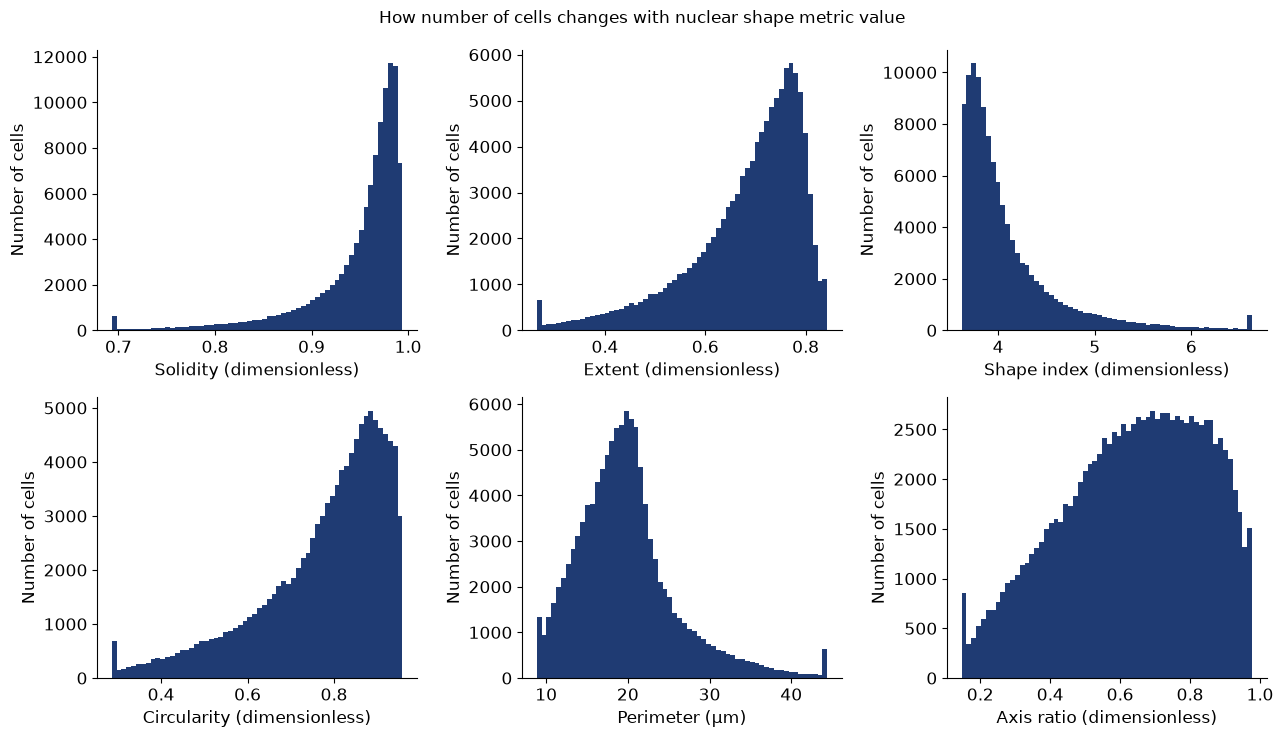

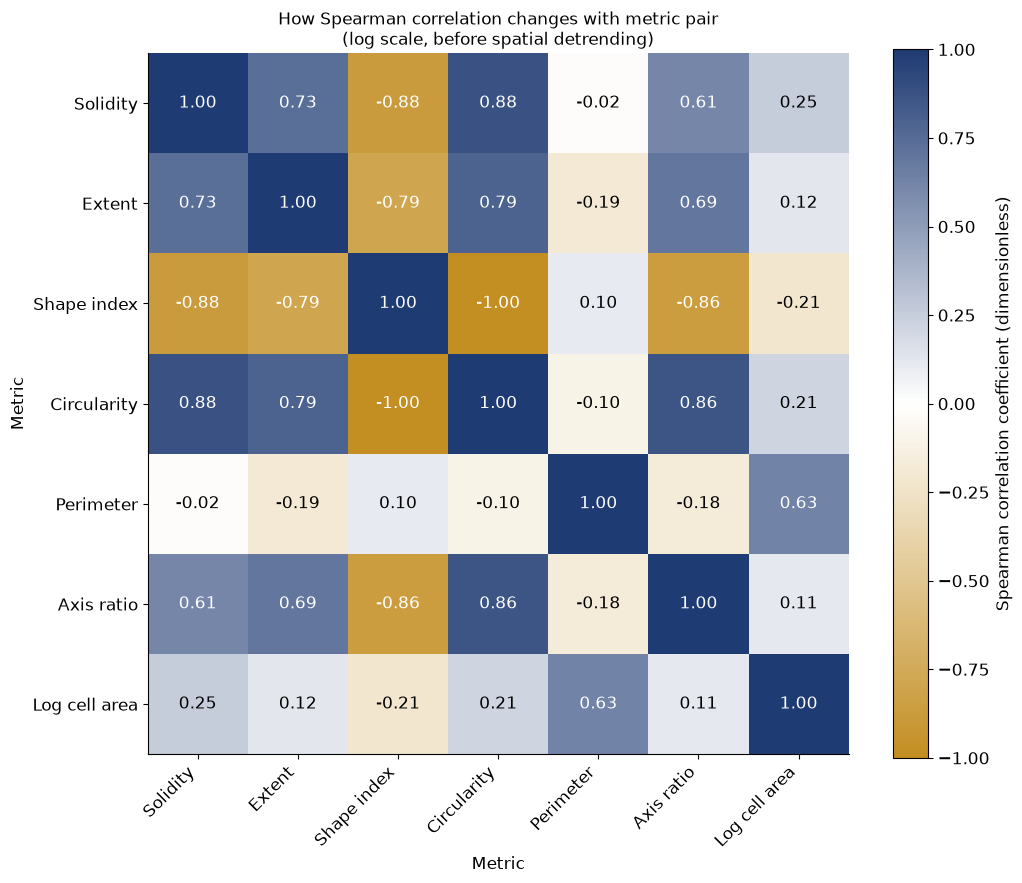

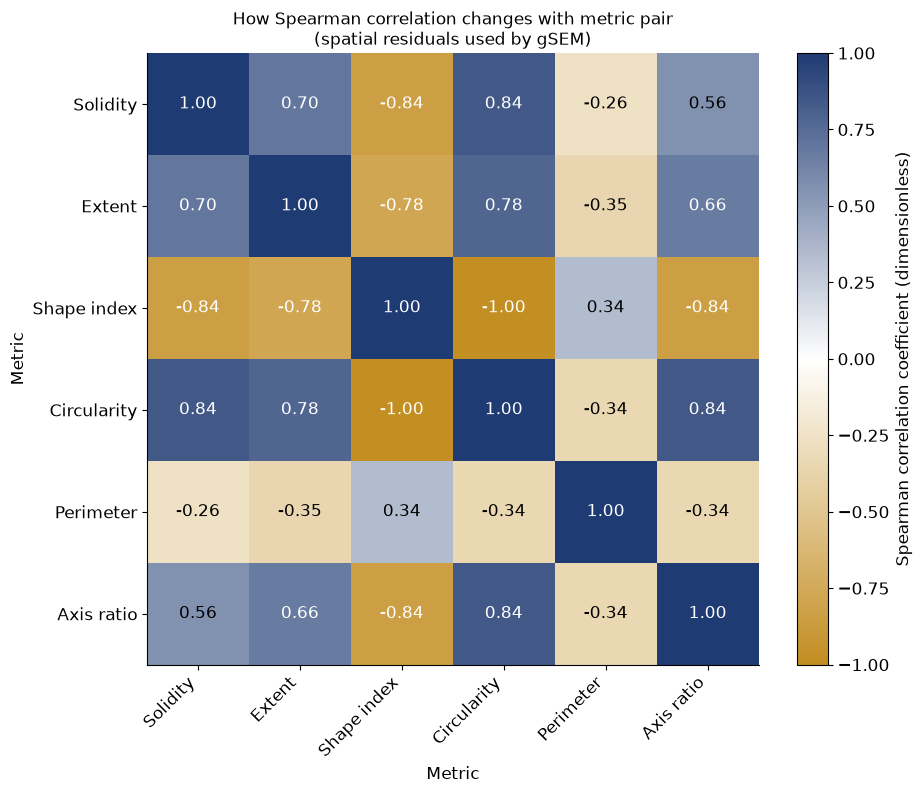

  volcano_solidity: checked - no overlapping text


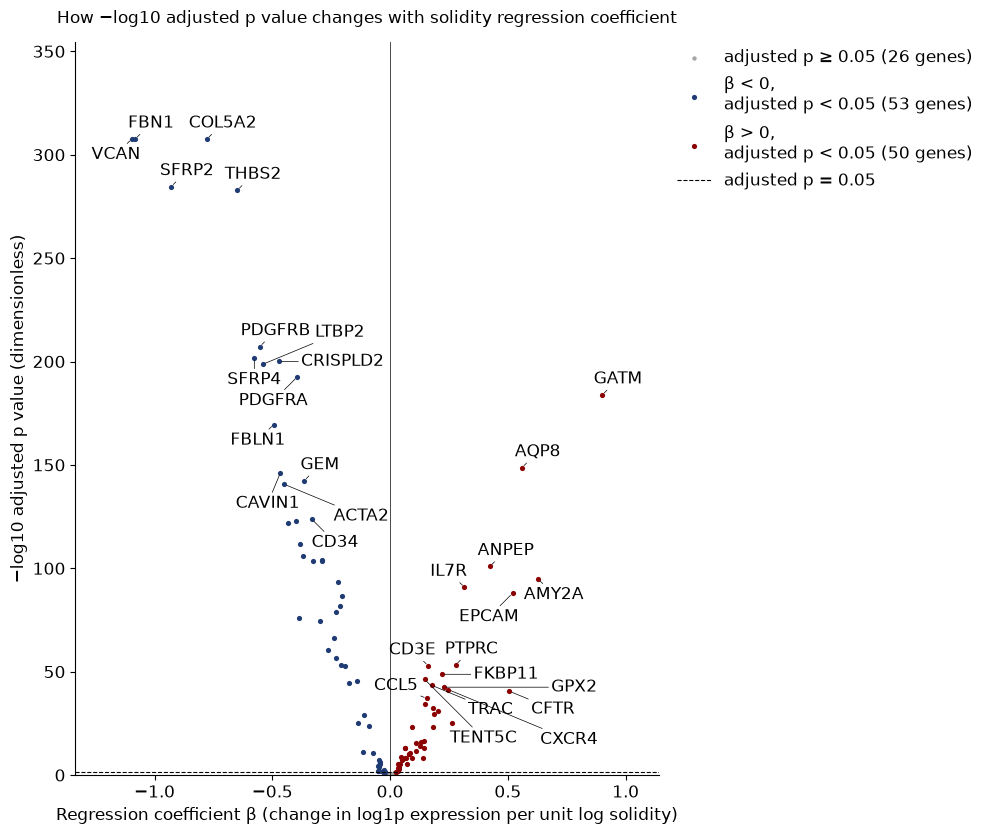

  volcano_extent: checked - no overlapping text


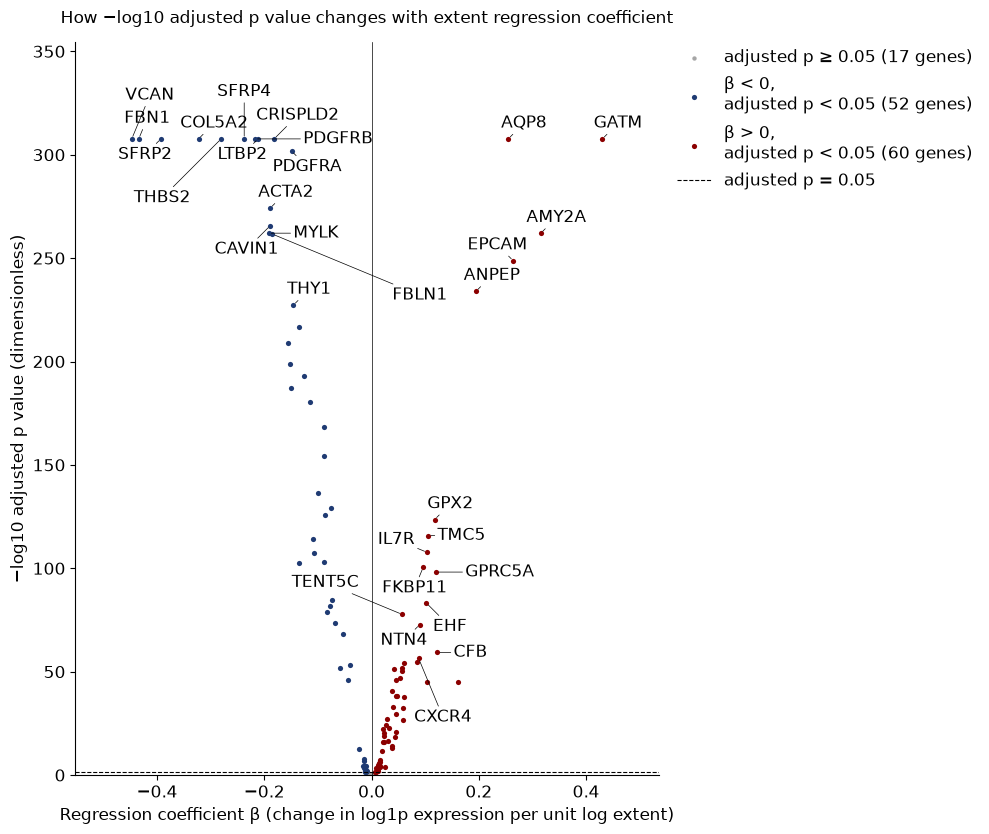

  volcano_shape_index: checked - no overlapping text


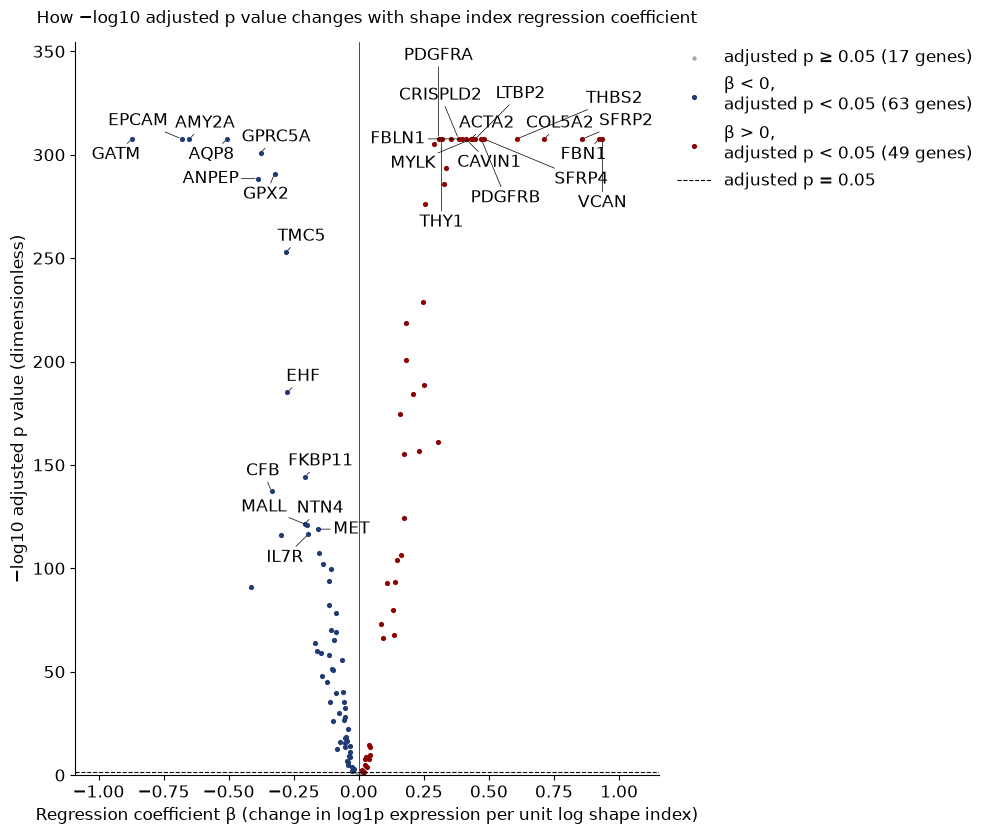

  volcano_circularity: checked - no overlapping text


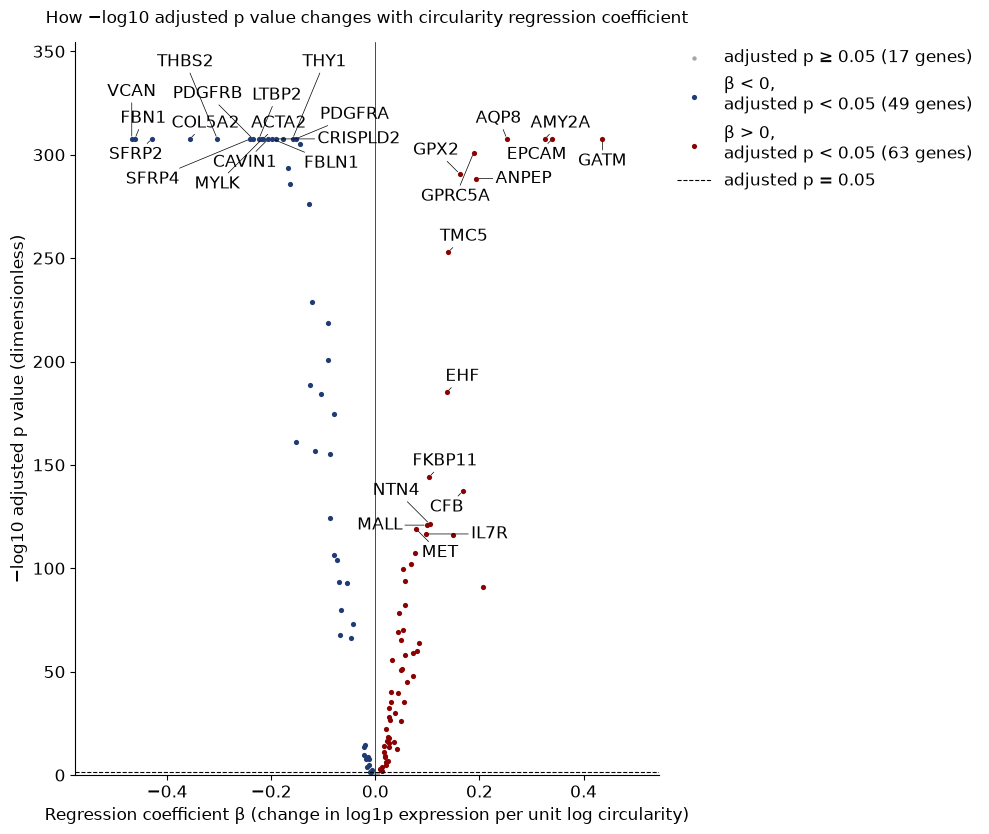

  volcano_perimeter: checked - no overlapping text


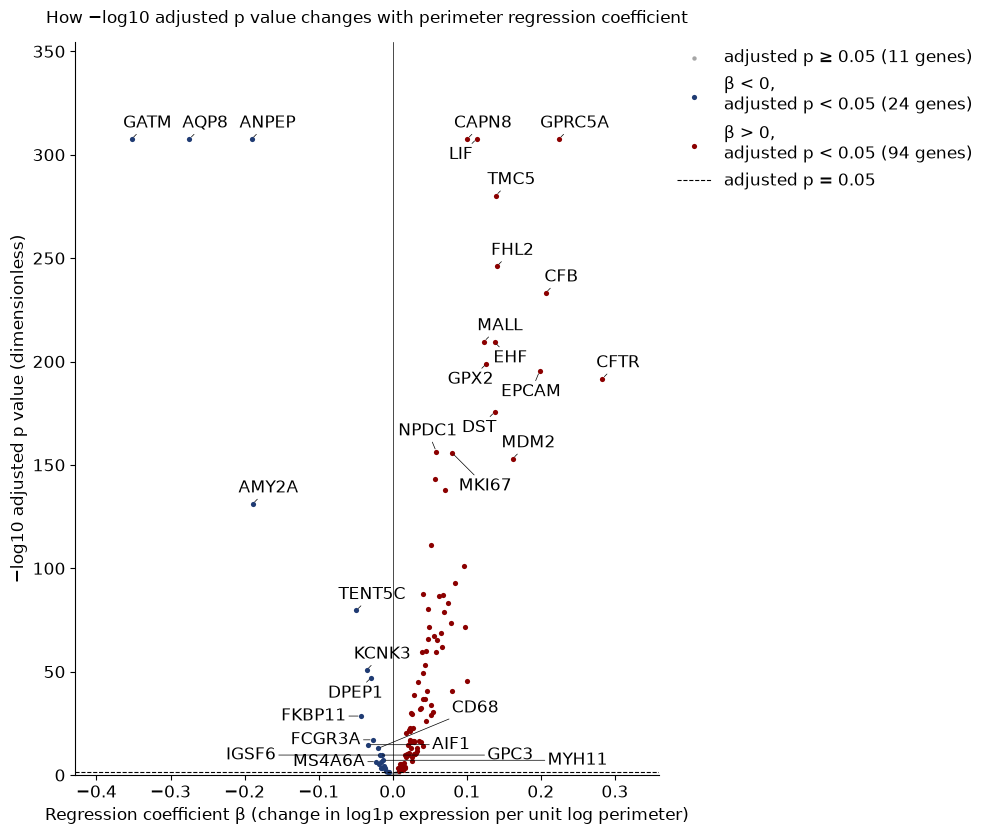

  volcano_axis_ratio: checked - no overlapping text


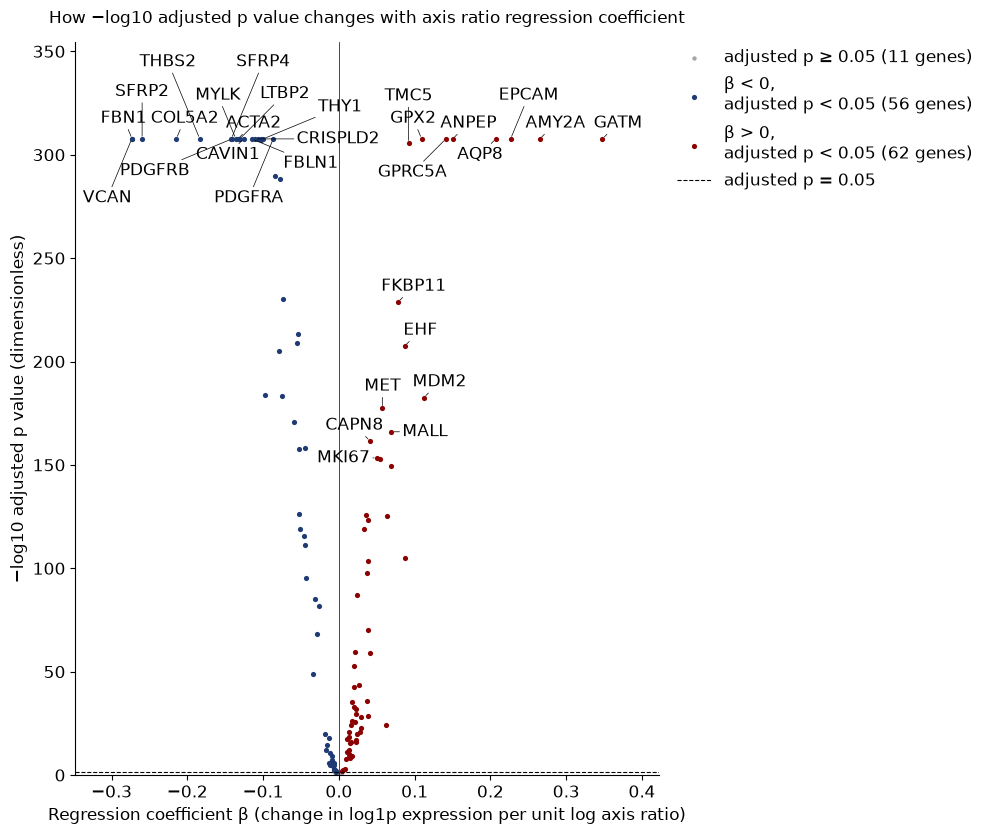

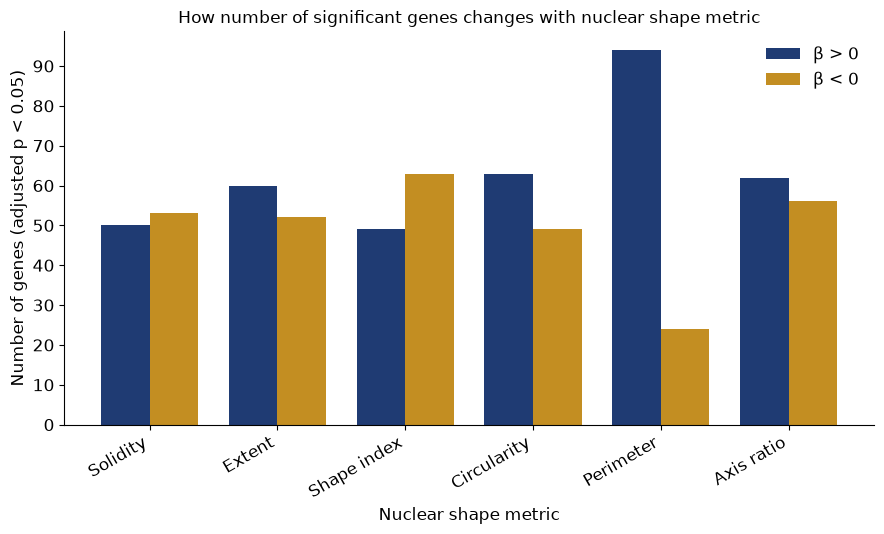

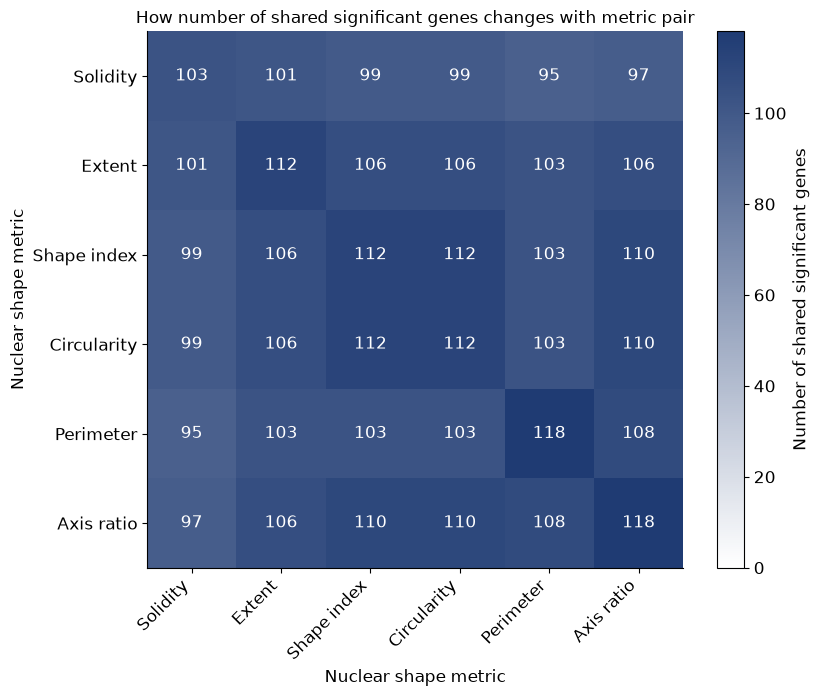

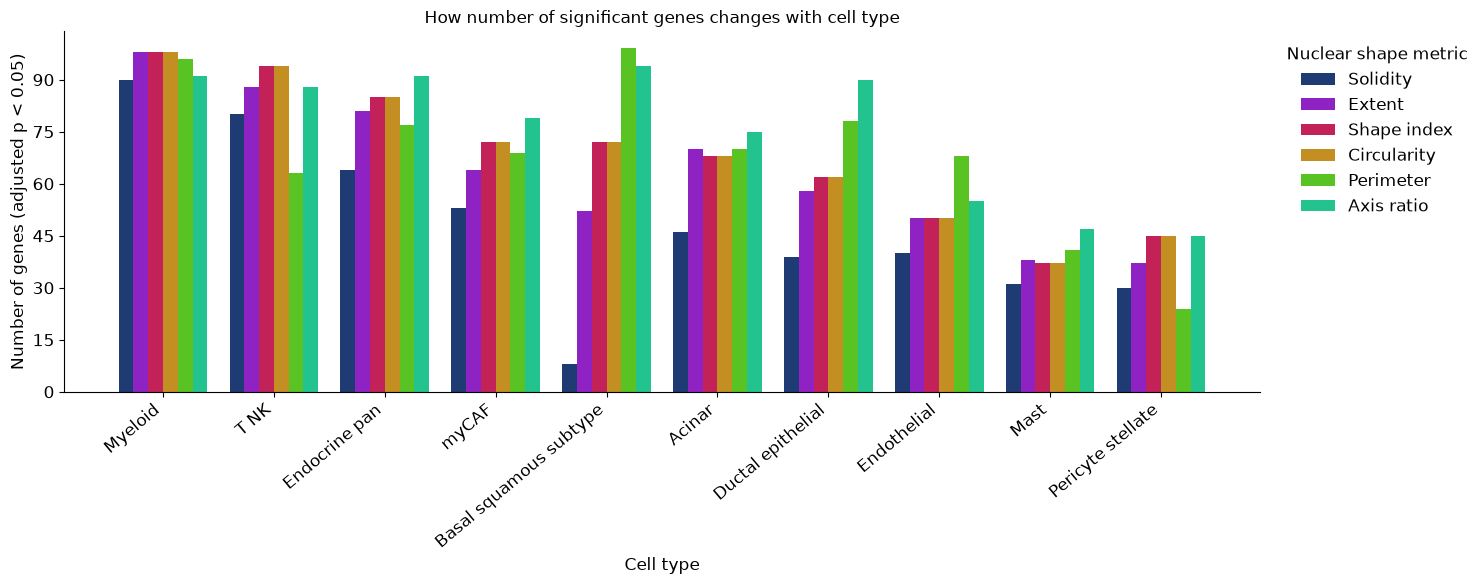

  volcano_blocked_solidity: checked - no overlapping text


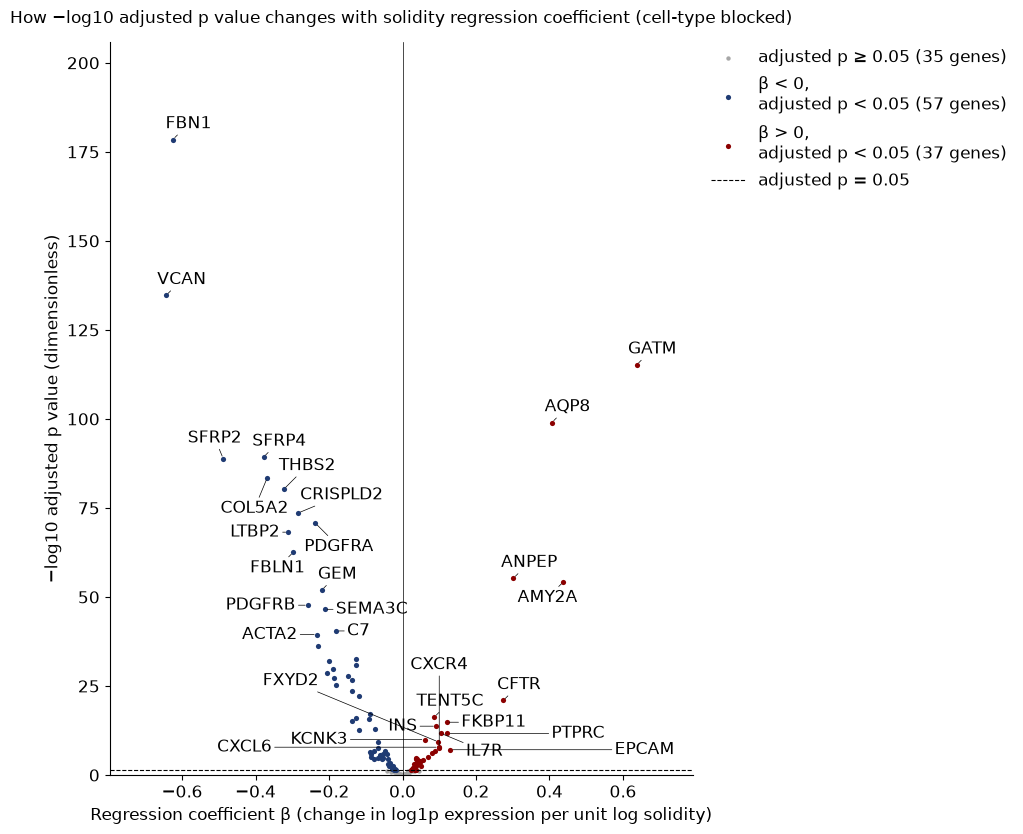

  volcano_blocked_extent: checked - no overlapping text


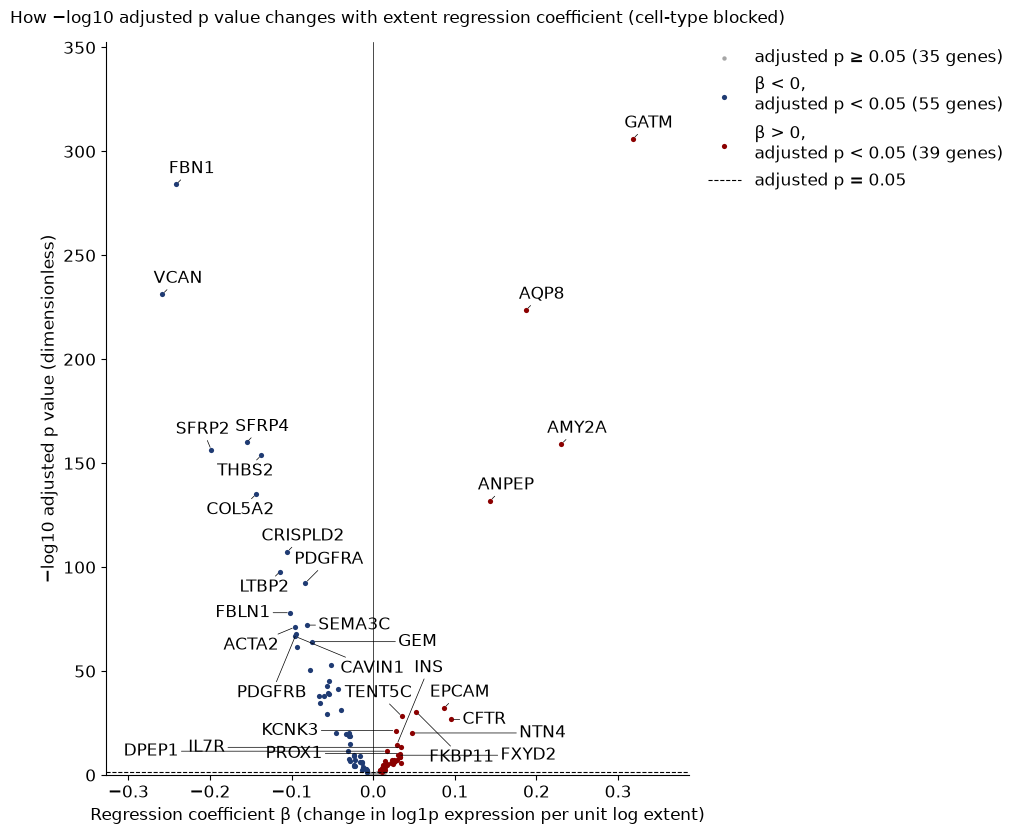

  volcano_blocked_shape_index: checked - no overlapping text


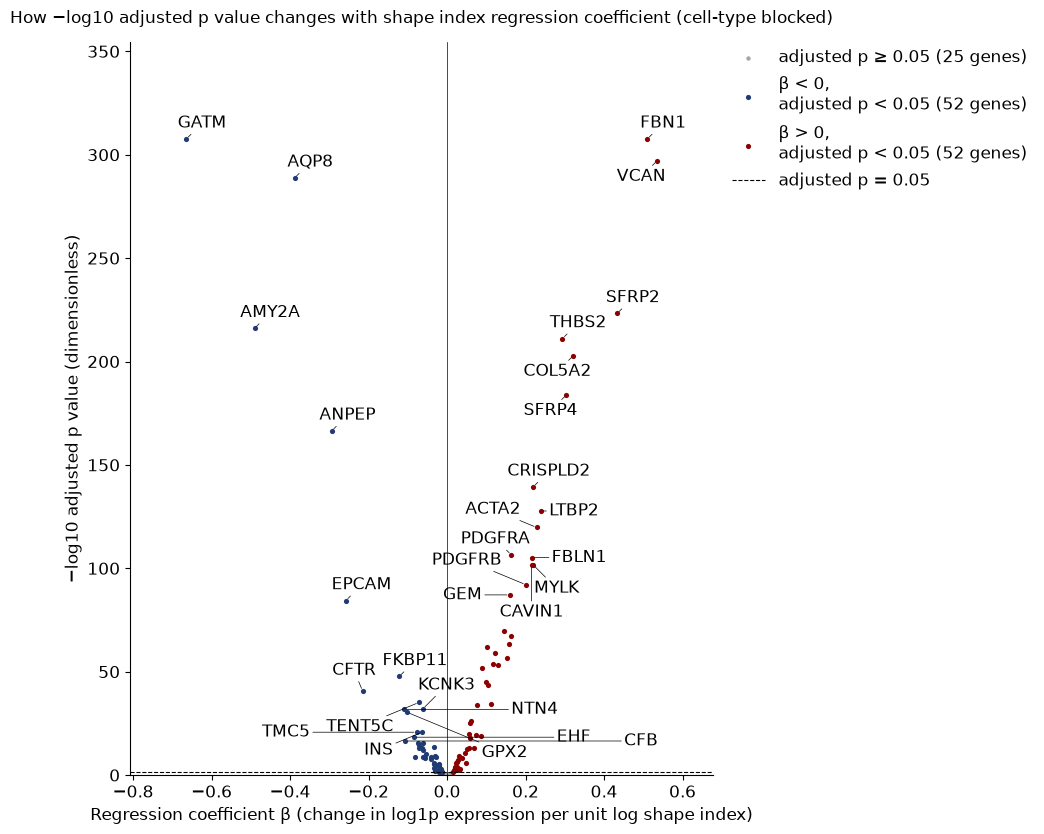

  volcano_blocked_circularity: checked - no overlapping text


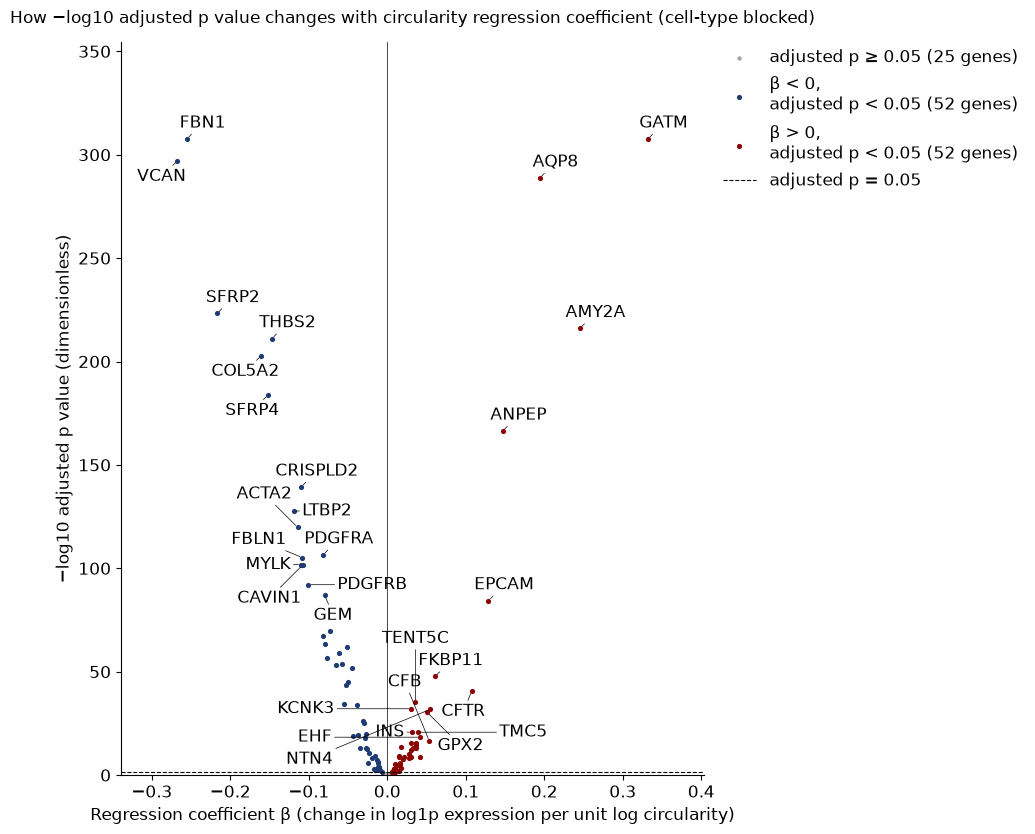

  volcano_blocked_perimeter: checked - no overlapping text


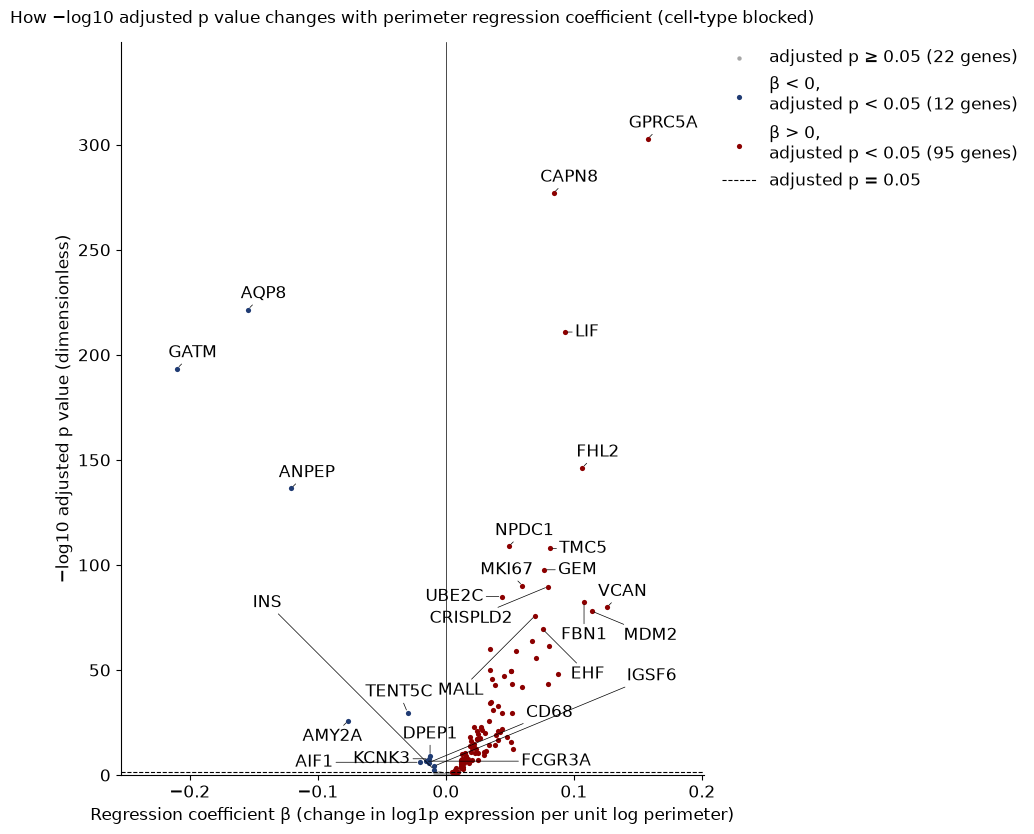

  volcano_blocked_axis_ratio: checked - no overlapping text


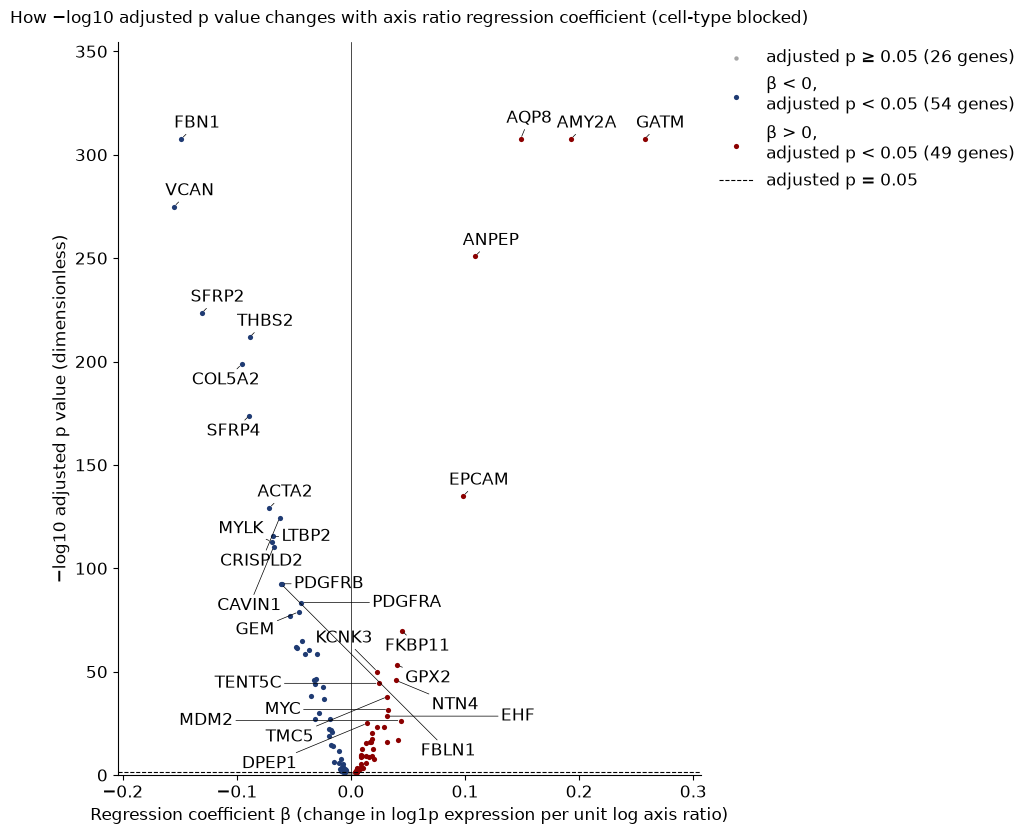

figures written to c:\MechanomeBioRepos\nuclear_shape\outputs\pancreas\figures

========== lung ==========


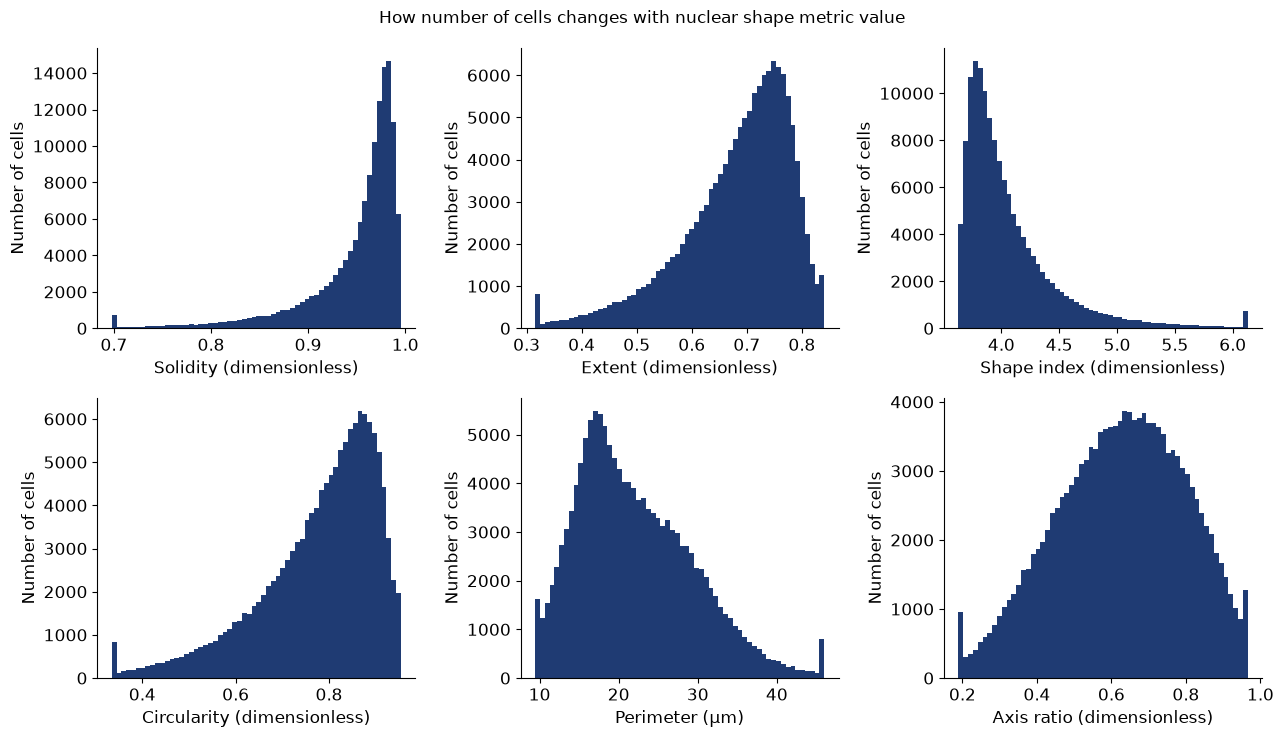

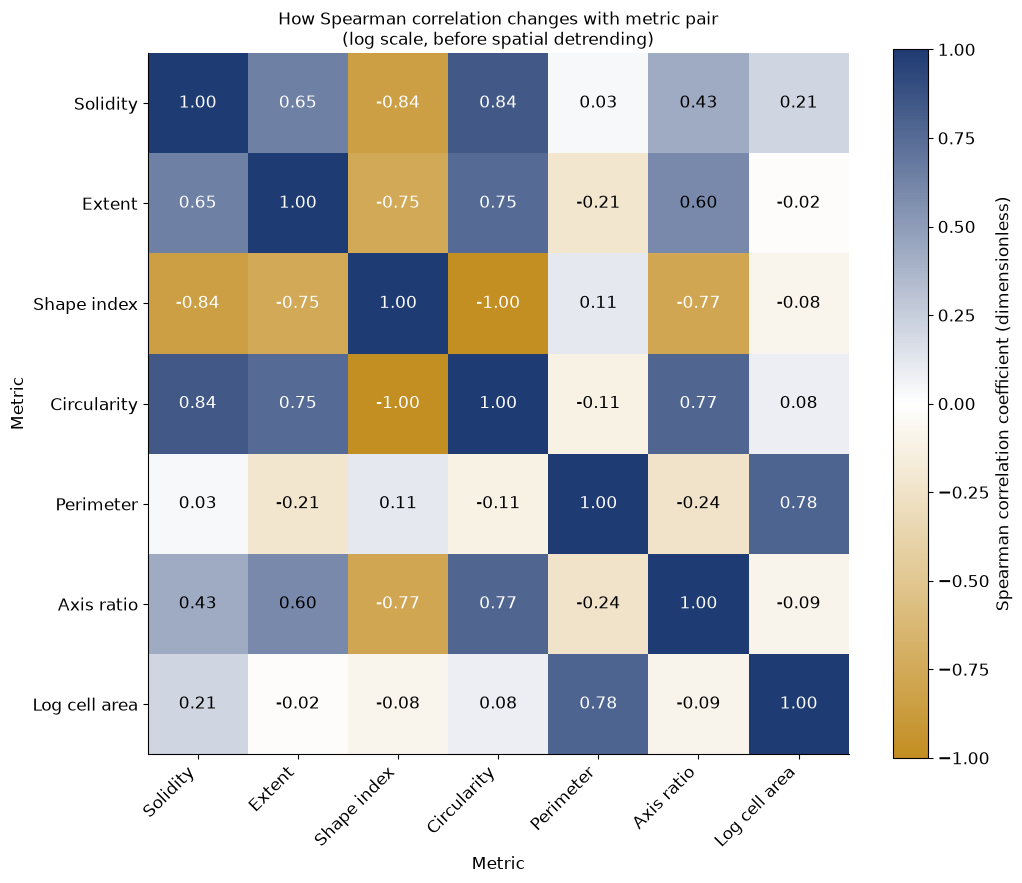

FileNotFoundError: [Errno 2] No such file or directory: 'c:\\MechanomeBioRepos\\nuclear_shape\\outputs\\lung\\plot_data\\metric_collinearity_after_detrending.csv'

In [6]:
# © 2026 Mechanome Bio. Proprietary and confidential.
# CELL 3: draw every figure for every tissue.
for dataset_name in DATASETS_TO_PLOT:
    plot_data_folder = REPOSITORY_FOLDER / "outputs" / dataset_name / "plot_data"
    figure_folder = REPOSITORY_FOLDER / "outputs" / dataset_name / "figures"
    if not plot_data_folder.exists():
        print(f"{dataset_name}: no plot_data folder yet - run the R notebook for this tissue first")
        continue
    figure_folder.mkdir(parents=True, exist_ok=True)
    print(f"\n========== {dataset_name} ==========")

    plot_metric_distributions(plot_data_folder, figure_folder)
    plot_correlation_heatmap(plot_data_folder, figure_folder, "metric_collinearity_before_detrending",
                             "log scale, before spatial detrending")
    plot_correlation_heatmap(plot_data_folder, figure_folder, "metric_collinearity_after_detrending",
                             "spatial residuals used by gSEM")
    for metric in SHAPE_METRICS:
        plot_volcano(plot_data_folder, figure_folder, f"volcano_{metric}", metric)
    plot_hit_counts(plot_data_folder, figure_folder)
    plot_hit_overlap(plot_data_folder, figure_folder)

    # Pancreas only (needs the cell-type step of the R notebook).
    plot_cell_type_hit_counts(plot_data_folder, figure_folder)
    for metric in SHAPE_METRICS:
        if (plot_data_folder / f"volcano_blocked_{metric}.csv").exists():
            plot_volcano(plot_data_folder, figure_folder, f"volcano_blocked_{metric}", metric,
                         subtitle_suffix=" (cell-type blocked)")

    print(f"figures written to {figure_folder}")